## 1. Libraries and paths

Required libraries: `pandas`, `numpy`, `matplotlib`, `requests`, `lxml`, and `beautifulsoup4`. Install them with `python -m pip install -r requirements.txt` if needed.

In [ ]:
from pathlib import Path
from io import StringIO
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "raw_company_data.csv").exists():
    candidates = list(ROOT.rglob("raw_company_data.csv"))
    if candidates:
        ROOT = candidates[0].parent

RAW_PATH = ROOT / "raw_company_data.csv"
CLEAN_PATH = ROOT / "clean_company_data.csv"
FEATURE_PATH = ROOT / "engineered_company_features.csv"
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
print("Working directory:", ROOT)
print("Raw data snapshot already available:", RAW_PATH.exists())

Working directory: /mnt/data/Feature_Engineering_Assignment_Final
Raw data snapshot already available: True


## 2. Collect the tabular data by web scraping

Source page: [List of largest companies in the United States by revenue](https://en.wikipedia.org/wiki/List_of_largest_companies_in_the_United_States_by_revenue). The script requests the HTML page, identifies the table from its headers, extracts the seven data columns, parses numbers, and saves the result as a CSV with the source URL. The request is attempted when this cell runs.

If network access is unavailable, the included CSV snapshot from the same public table is used so the cleaning and feature-engineering steps remain reproducible. To refresh the dataset from the live page, run this notebook or execute `python scrape_company_data.py` on an internet-connected computer.

In [ ]:
SOURCE_URL = "https://en.wikipedia.org/wiki/List_of_largest_companies_in_the_United_States_by_revenue"


def _norm_header(value):
    return re.sub(r"[^a-z0-9]+", " ", str(value).lower()).strip()


def _parse_number(value, percentage=False):
    if pd.isna(value):
        return np.nan
    text = str(value).replace("−", "-").replace("–", "-").strip()
    match = re.search(r"[-+]?\s*\d[\d,]*(?:\.\d+)?", text)
    if not match:
        return np.nan
    token = match.group(0).replace(",", "").replace(" ", "")
    number = float(token)
    if percentage and "decrease" in text.lower() and not token.startswith("-"):
        number = -abs(number)
    return number


def scrape_company_table(url=SOURCE_URL, output_path=RAW_PATH):
    """Scrape the revenue table and return normalized tabular data."""
    import requests
    response = requests.get(
        url,
        headers={"User-Agent": "Student Feature Engineering Assignment/1.0 (educational use)"},
        timeout=(3, 6),
    )
    response.raise_for_status()
    tables = pd.read_html(StringIO(response.text))

    for table in tables:
        if isinstance(table.columns, pd.MultiIndex):
            headers = [" ".join(str(p) for p in col if "unnamed" not in str(p).lower()).strip() for col in table.columns]
        else:
            headers = [str(c).strip() for c in table.columns]
        normalized = [_norm_header(h) for h in headers]

        def find_column(predicate):
            return next((j for j, name in enumerate(normalized) if predicate(name)), None)

        positions = {
            "Rank": find_column(lambda x: x == "rank"),
            "Company": find_column(lambda x: x in {"name", "company", "security"} or x.startswith("name ")),
            "Industry": find_column(lambda x: x == "industry" or x.startswith("industry ")),
            "Revenue_USD_Millions": find_column(lambda x: "revenue" in x and "growth" not in x),
            "Revenue_Growth_Pct": find_column(lambda x: "revenue" in x and "growth" in x),
            "Employees": find_column(lambda x: x == "employees" or x.startswith("employees ")),
            "Headquarters": find_column(lambda x: "headquarters" in x),
        }
        if any(pos is None for pos in positions.values()):
            continue
        result = pd.DataFrame({name: table.iloc[:, pos] for name, pos in positions.items()})
        result["Rank"] = pd.to_numeric(result["Rank"], errors="coerce")
        result["Revenue_USD_Millions"] = result["Revenue_USD_Millions"].map(_parse_number)
        result["Revenue_Growth_Pct"] = result["Revenue_Growth_Pct"].map(lambda x: _parse_number(x, percentage=True))
        result["Employees"] = result["Employees"].map(_parse_number)
        for col in ["Company", "Industry", "Headquarters"]:
            result[col] = result[col].astype("string").str.strip()
        result = result.dropna(subset=["Rank", "Company", "Revenue_USD_Millions", "Employees"])
        result["Rank"] = result["Rank"].astype(int)
        result["Employees"] = result["Employees"].round().astype("Int64")
        result["Source_URL"] = url
        result = result[["Rank", "Company", "Industry", "Revenue_USD_Millions", "Revenue_Growth_Pct", "Employees", "Headquarters", "Source_URL"]]
        result = result.drop_duplicates(subset="Company").sort_values("Rank").reset_index(drop=True)
        if len(result) < 80:
            continue
        result.to_csv(output_path, index=False)
        return result
    raise RuntimeError("Expected company table was not found or too few rows were extracted.")


scrape_status = ""
try:
    raw_live = scrape_company_table()
    scrape_status = "Live scrape succeeded"
    raw = raw_live.copy()
except Exception as exc:
    if RAW_PATH.exists():
        raw = pd.read_csv(RAW_PATH)
        scrape_status = f"Live scrape unavailable ({type(exc).__name__}); using the supplied source snapshot"
    else:
        # In Google Colab, upload raw_company_data.csv from the assignment package if scraping is blocked.
        try:
            from google.colab import files
            print("Live scraping failed. Upload raw_company_data.csv from the assignment package.")
            uploaded = files.upload()
            if "raw_company_data.csv" not in uploaded:
                raise FileNotFoundError("Please upload a file named raw_company_data.csv.")
            RAW_PATH.write_bytes(uploaded["raw_company_data.csv"])
            raw = pd.read_csv(RAW_PATH)
            scrape_status = f"Live scrape unavailable ({type(exc).__name__}); using the uploaded source snapshot"
        except ImportError:
            raise RuntimeError(
                f"Live scrape failed ({exc}) and raw_company_data.csv is missing. "
                "Place the CSV beside the notebook or run in Google Colab and upload it when prompted."
            ) from exc

print(scrape_status)
print(f"Rows captured: {len(raw)} | Source: {SOURCE_URL}")
display(raw.head(8))

Live scrape unavailable (ConnectionError); using the supplied source snapshot
Rows captured: 100 | Source: https://en.wikipedia.org/wiki/List_of_largest_companies_in_the_United_States_by_revenue


,Rank,Company,Industry,Revenue_USD_Millions,Revenue_Growth_Pct,Employees,Headquarters,Source_URL
0,1,Walmart,Retail,680985,5.1,2100000,"Bentonville, Arkansas",https://en.wikipedia.org/wiki/List_of_largest_...
1,2,Amazon,Retail and cloud computing,637959,11.0,1556000,"Seattle, Washington",https://en.wikipedia.org/wiki/List_of_largest_...
2,3,UnitedHealth Group,Healthcare,400278,7.7,400000,"Minnetonka, Minnesota",https://en.wikipedia.org/wiki/List_of_largest_...
3,4,Apple,Technology,391035,2.0,164000,"Cupertino, California",https://en.wikipedia.org/wiki/List_of_largest_...
4,5,CVS Health,Healthcare,372809,4.2,259500,"Woonsocket, Rhode Island",https://en.wikipedia.org/wiki/List_of_largest_...
5,6,Berkshire Hathaway,Conglomerate,371433,1.9,392400,"Omaha, Nebraska",https://en.wikipedia.org/wiki/List_of_largest_...
6,7,Alphabet,Technology and cloud computing,350018,13.9,183323,"Mountain View, California",https://en.wikipedia.org/wiki/List_of_largest_...
7,8,Exxon Mobil,Petroleum,349595,1.5,60900,"Spring, Texas",https://en.wikipedia.org/wiki/List_of_largest_...


## 3. Inspect and clean the raw table

Cleaning rules:

1. Standardize text fields and convert financial values to numeric types.
2. Remove duplicate companies and duplicate ranks.
3. Treat non-positive revenue or employee counts as invalid for ratio calculations.
4. Keep negative revenue growth because it represents a real contraction.
5. Do not delete large companies solely because an IQR rule flags them: they are legitimate observations in a top-revenue ranking. Use log transforms to reduce skew and retain the raw values for auditability.

In [ ]:
data = raw.copy()

required_columns = ["Rank", "Company", "Industry", "Revenue_USD_Millions", "Revenue_Growth_Pct", "Employees", "Headquarters"]
missing_columns = [col for col in required_columns if col not in data.columns]
if missing_columns:
    raise ValueError(f"Required columns missing from scrape: {missing_columns}")

for col in ["Company", "Industry", "Headquarters"]:
    data[col] = data[col].astype("string").str.strip()
for col in ["Rank", "Revenue_USD_Millions", "Revenue_Growth_Pct", "Employees"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

rows_before = len(data)
duplicate_companies = int(data["Company"].duplicated().sum())
duplicate_ranks = int(data["Rank"].duplicated().sum())
data = data.drop_duplicates(subset="Company", keep="first")
data = data.drop_duplicates(subset="Rank", keep="first")
data.loc[data["Revenue_USD_Millions"] <= 0, "Revenue_USD_Millions"] = np.nan
data.loc[data["Employees"] <= 0, "Employees"] = np.nan

quality_summary = pd.DataFrame({
    "Check": ["Rows before duplicate removal", "Duplicate company names", "Duplicate ranks", "Missing values after type conversion", "Invalid/non-positive revenue", "Invalid/non-positive employees"],
    "Result": [rows_before, duplicate_companies, duplicate_ranks, int(data[required_columns].isna().sum().sum()), int(data["Revenue_USD_Millions"].isna().sum()), int(data["Employees"].isna().sum())]
})
display(quality_summary)
print("Missing values by column:")
display(data[required_columns].isna().sum().rename("Missing count").to_frame())

# The supplied snapshot is complete; for a refreshed scrape, retain records with missing growth
# but remove rows that cannot support the core revenue-per-employee feature.
data = data.dropna(subset=["Company", "Rank", "Revenue_USD_Millions", "Employees"]).copy()
data["Rank"] = data["Rank"].astype(int)
data["Employees"] = data["Employees"].round().astype("int64")
data = data.sort_values("Rank").reset_index(drop=True)
data.to_csv(CLEAN_PATH, index=False)
print(f"Clean table: {data.shape[0]} rows x {data.shape[1]} columns")

,Check,Result
0,Rows before duplicate removal,100
1,Duplicate company names,0
2,Duplicate ranks,0
3,Missing values after type conversion,0
4,Invalid/non-positive revenue,0
5,Invalid/non-positive employees,0


Missing values by column:


,Missing count
Rank,0
Company,0
Industry,0
Revenue_USD_Millions,0
Revenue_Growth_Pct,0
Employees,0
Headquarters,0


Clean table: 100 rows x 8 columns


## 4. Statistical inspection before engineering

Summary statistics show scale and spread. The interquartile range is used to *flag* extreme values:

\[
IQR=Q_3-Q_1,\qquad \text{outlier if }x<Q_1-1.5IQR\text{ or }x>Q_3+1.5IQR.
\]

An IQR flag is not proof of an error. For a dataset intentionally containing the largest companies, very high revenue or employee counts are expected, so these values are retained.

In [ ]:
numeric_summary = data[["Revenue_USD_Millions", "Revenue_Growth_Pct", "Employees"]].describe().T
numeric_summary["Skewness"] = data[["Revenue_USD_Millions", "Revenue_Growth_Pct", "Employees"]].skew(numeric_only=True)
display(numeric_summary.round(3))

outlier_rows = []
for col in ["Revenue_USD_Millions", "Revenue_Growth_Pct", "Employees"]:
    series = data[col].dropna()
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((series < low) | (series > high)).sum())
    outlier_rows.append({"Variable": col, "Q1": q1, "Q3": q3, "IQR": iqr, "IQR-flagged rows": count, "Handling": "Retain; inspect and transform if needed"})
display(pd.DataFrame(outlier_rows).round(3))

,count,mean,std,min,25%,50%,75%,max,Skewness
Revenue_USD_Millions,100.0,130499.620,116235.763,45043.0,56804.75,84784.50,148911.000,680985.0,2.530
Revenue_Growth_Pct,100.0,7.689,15.258,-15.6,0.90,5.05,11.125,114.2,4.149
Employees,100.0,161977.670,268276.159,4200.0,44750.00,85700.00,188662.500,2100000.0,5.358


,Variable,Q1,Q3,IQR,IQR-flagged rows,Handling
0,Revenue_USD_Millions,56804.75,148911.000,92106.250,10,Retain; inspect and transform if needed
1,Revenue_Growth_Pct,0.90,11.125,10.225,8,Retain; inspect and transform if needed
2,Employees,44750.00,188662.500,143912.500,6,Retain; inspect and transform if needed


## 5. Feature engineering and mathematical justification

### A. Unit conversion and productivity proxy

The source reports revenue in **USD millions**. Convert it to dollars before calculating a per-employee measure:

\[
R_{USD}=10^6R_{million},\qquad P=\frac{R_{USD}}{E}.
\]

\(P\) is revenue per employee. It is a *revenue-intensity proxy*, not profit per employee or a definitive measure of worker productivity; sectors with different business models are not directly comparable.

### B. Percentage conversion and growth categories

\[
g_{decimal}=\frac{g_{percent}}{100}.
\]

For interpretation, classify growth as contraction if \(g<0\), low if \(0\le g<5\), moderate if \(5\le g\le15\), and high if \(g>15\). These are transparent descriptive bins, not learned labels.

### C. Log transformation

\[
x_{log}=\log(1+x),\quad x\ge0.
\]

Revenue and employee counts tend to be right-skewed. A log transform compresses large magnitudes while preserving order and makes charts more readable. `log1p` is used so zero is mathematically defined; negative financial values would require separate treatment and are not silently passed into this transform.

### D. Standardization and min-max scaling

\[
z_i=\frac{x_i-\mu_x}{\sigma_x},\qquad x_i^{scaled}=\frac{x_i-x_{min}}{x_{max}-x_{min}}.
\]

Z-scores express distance from the sample mean in standard-deviation units. Min-max scaling maps the sample range to \([0,1]\). These versions are included to demonstrate feature preparation. For predictive modelling, fit scalers on training rows only to avoid information leakage.

### E. Categorical features

Industry names are grouped into broader categories with explicit keyword rules, then one-hot encoded. One-hot encoding represents categories as binary columns without introducing a false numerical ordering. Revenue and employee size tiers are quartiles *within this dataset*, so their thresholds will change if the source table changes.

In [ ]:
def map_industry(industry):
    text = str(industry).lower()
    if any(k in text for k in ["petroleum", "oil", "gas", "energy", "pipeline"]):
        return "Energy & Petroleum"
    if any(k in text for k in ["financial", "insurance", "bank", "finance", "investment"]):
        return "Financial Services"
    if any(k in text for k in ["food", "beverage", "agriculture", "grocery"]):
        return "Food & Agriculture"
    if any(k in text for k in ["health", "pharma", "pharmaceutical", "hospital", "medical"]):
        return "Healthcare & Pharma"
    if any(k in text for k in ["technology", "cloud", "software", "semiconductor", "computer", "electronics", "information technology"]):
        return "Technology"
    if any(k in text for k in ["telecommunication", "telecom", "media", "cable", "broadcast"]):
        return "Telecom & Media"
    if any(k in text for k in ["retail", "consumer", "department store", "home improvement", "e-commerce"]):
        return "Retail & Consumer"
    if any(k in text for k in ["aerospace", "defense", "automotive", "airline", "transportation", "industrial", "machinery", "shipping", "conglomerate", "manufacturing"]):
        return "Transport & Industrial"
    return "Other"

engineered = data.copy()
engineered["Revenue_USD"] = engineered["Revenue_USD_Millions"] * 1_000_000
engineered["Revenue_Growth_Decimal"] = engineered["Revenue_Growth_Pct"] / 100
engineered["Revenue_Per_Employee_USD"] = engineered["Revenue_USD"] / engineered["Employees"]
engineered["Revenue_Log1p"] = np.log1p(engineered["Revenue_USD"].clip(lower=0))
engineered["Employees_Log1p"] = np.log1p(engineered["Employees"].clip(lower=0))
engineered["Revenue_Per_Employee_Log1p"] = np.log1p(engineered["Revenue_Per_Employee_USD"].clip(lower=0))

# Transparent growth bands: negative / [0,5) / [5,15] / >15 percent.
growth = engineered["Revenue_Growth_Pct"]
engineered["Revenue_Growth_Category"] = np.select(
    [growth.isna(), growth < 0, growth < 5, growth <= 15],
    ["Unknown", "Contraction (<0%)", "Low growth (0 to <5%)", "Moderate growth (5 to 15%)"],
    default="High growth (>15%)",
)
engineered["Industry_Group"] = engineered["Industry"].map(map_industry)
engineered["Revenue_Tier"] = pd.qcut(
    engineered["Revenue_USD_Millions"].rank(method="first"),
    q=4,
    labels=["Q1 - lower revenue", "Q2 - lower-middle", "Q3 - upper-middle", "Q4 - highest revenue"],
)
engineered["Employee_Size_Band"] = pd.qcut(
    engineered["Employees"].rank(method="first"),
    q=4,
    labels=["Q1 - fewer employees", "Q2 - lower-middle", "Q3 - upper-middle", "Q4 - most employees"],
)

scale_columns = {
    "Revenue_USD": "Revenue",
    "Revenue_Growth_Pct": "Growth",
    "Employees": "Employees",
    "Revenue_Per_Employee_USD": "Revenue_Per_Employee",
}
for source_col, prefix in scale_columns.items():
    values = pd.to_numeric(engineered[source_col], errors="coerce")
    std = values.std(ddof=0)
    engineered[f"{prefix}_ZScore"] = (values - values.mean()) / (std if std and std > 0 else 1)
    minimum, maximum = values.min(), values.max()
    span = maximum - minimum
    engineered[f"{prefix}_MinMax"] = (values - minimum) / (span if span and span > 0 else 1)

industry_dummies = pd.get_dummies(engineered["Industry_Group"], prefix="Industry", dtype=int)
engineered = pd.concat([engineered, industry_dummies], axis=1)
engineered.to_csv(FEATURE_PATH, index=False)
print(f"Engineered table saved: {FEATURE_PATH}")
print(f"Rows: {len(engineered)} | Columns: {len(engineered.columns)} | One-hot industry columns: {len(industry_dummies.columns)}")
display(engineered.head(8))

Engineered table saved: /mnt/data/Feature_Engineering_Assignment_Final/engineered_company_features.csv
Rows: 100 | Columns: 35 | One-hot industry columns: 9


,Rank,Company,Industry,Revenue_USD_Millions,Revenue_Growth_Pct,Employees,Headquarters,Source_URL,Revenue_USD,Revenue_Growth_Decimal,Revenue_Per_Employee_USD,Revenue_Log1p,Employees_Log1p,Revenue_Per_Employee_Log1p,Revenue_Growth_Category,Industry_Group,Revenue_Tier,Employee_Size_Band,Revenue_ZScore,Revenue_MinMax,Growth_ZScore,Growth_MinMax,Employees_ZScore,Employees_MinMax,Revenue_Per_Employee_ZScore,Revenue_Per_Employee_MinMax,Industry_Energy & Petroleum,Industry_Financial Services,Industry_Food & Agriculture,Industry_Healthcare & Pharma,Industry_Other,Industry_Retail & Consumer,Industry_Technology,Industry_Telecom & Media,Industry_Transport & Industrial
0,1,Walmart,Retail,680985.0,5.1,2100000,"Bentonville, Arkansas",https://en.wikipedia.org/wiki/List_of_largest_...,6.809850e+11,0.051,3.242786e+05,27.246806,14.557448,12.689361,Moderate growth (5 to 15%),Retail & Consumer,Q4 - highest revenue,Q4 - most employees,4.759797,1.000000,-0.170534,0.159476,7.260376,1.000000,-0.547008,0.007687,0,0,0,0,0,1,0,0,0
1,2,Amazon,Retail and cloud computing,637959.0,11.0,1556000,"Seattle, Washington",https://en.wikipedia.org/wiki/List_of_largest_...,6.379590e+11,0.110,4.099994e+05,27.181540,14.257630,12.923913,Moderate growth (5 to 15%),Technology,Q4 - highest revenue,Q4 - most employees,4.387771,0.932343,0.218091,0.204931,5.222399,0.740433,-0.524138,0.011576,0,0,0,0,0,0,1,0,0
2,3,UnitedHealth Group,Healthcare,400278.0,7.7,400000,"Minnetonka, Minnesota",https://en.wikipedia.org/wiki/List_of_largest_...,4.002780e+11,0.077,1.000695e+06,26.715425,12.899222,13.816206,Moderate growth (5 to 15%),Healthcare & Pharma,Q4 - highest revenue,Q4 - most employees,2.332651,0.558597,0.000725,0.179507,0.891698,0.188854,-0.366537,0.038374,0,0,0,1,0,0,0,0,0
3,4,Apple,Technology,391035.0,2.0,164000,"Cupertino, California",https://en.wikipedia.org/wiki/List_of_largest_...,3.910350e+11,0.020,2.384360e+06,26.692063,12.007628,14.684442,Low growth (0 to <5%),Technology,Q4 - highest revenue,Q3 - upper-middle,2.252731,0.544062,-0.374727,0.135593,0.007576,0.076248,0.002632,0.101147,0,0,0,0,0,0,1,0,0
4,5,CVS Health,Healthcare,372809.0,4.2,259500,"Woonsocket, Rhode Island",https://en.wikipedia.org/wiki/List_of_largest_...,3.728090e+11,0.042,1.436644e+06,26.644332,12.466516,14.177821,Low growth (0 to <5%),Healthcare & Pharma,Q4 - highest revenue,Q4 - most employees,2.095139,0.515402,-0.229816,0.152542,0.365346,0.121815,-0.250223,0.058152,0,0,0,1,0,0,0,0,0
5,6,Berkshire Hathaway,Conglomerate,371433.0,1.9,392400,"Omaha, Nebraska",https://en.wikipedia.org/wiki/List_of_largest_...,3.714330e+11,0.019,9.465673e+05,26.640634,12.880040,13.760598,Low growth (0 to <5%),Transport & Industrial,Q4 - highest revenue,Q4 - most employees,2.083241,0.513239,-0.381314,0.134823,0.863227,0.185228,-0.380978,0.035918,0,0,0,0,0,0,0,0,1
6,7,Alphabet,Technology and cloud computing,350018.0,13.9,183323,"Mountain View, California",https://en.wikipedia.org/wiki/List_of_largest_...,3.500180e+11,0.139,1.909297e+06,26.581250,12.119010,14.462246,Moderate growth (5 to 15%),Technology,Q4 - highest revenue,Q3 - upper-middle,1.898076,0.479564,0.409110,0.227273,0.079966,0.085468,-0.124117,0.079594,0,0,0,0,0,0,1,0,0
7,8,Exxon Mobil,Petroleum,349595.0,1.5,60900,"Spring, Texas",https://en.wikipedia.org/wiki/List_of_largest_...,3.495950e+11,0.015,5.740476e+06,26.580041,11.017005,15.563053,Low growth (0 to <5%),Energy & Petroleum,Q4 - highest revenue,Q2 - lower-middle,1.894418,0.478899,-0.407661,0.131741,-0.378665,0.027054,0.898062,0.253403,1,0,0,0,0,0,0,0,0


## 6. Feature catalog and selection reasoning

In [ ]:
feature_catalog = pd.DataFrame([
    ["Revenue_USD", "Revenue_USD_Millions × 1,000,000", "Consistent currency unit for later joins and formulas"],
    ["Revenue_Growth_Decimal", "Revenue_Growth_Pct / 100", "Machine-friendly growth rate (e.g. 7.5% becomes 0.075)"],
    ["Revenue_Per_Employee_USD", "Revenue_USD / Employees", "Scale-adjusted revenue-intensity proxy"],
    ["Revenue_Log1p", "log(1 + Revenue_USD)", "Compresses large scale differences"],
    ["Employees_Log1p", "log(1 + Employees)", "Reduces positive skew in workforce size"],
    ["Revenue_Per_Employee_Log1p", "log(1 + Revenue per employee)", "Compresses extreme ratio values"],
    ["Revenue_Growth_Category", "Rule-based bins of growth percentage", "Makes growth direction and magnitude interpretable"],
    ["Revenue_Tier / Employee_Size_Band", "Quartile bins", "Relative position within the current sample"],
    ["Industry_Group + Industry_*", "Rule-based broad groups + one-hot encoding", "Represents industry without ordinal coding"],
    ["*_ZScore", "(x - mean) / standard deviation", "Measures distance from sample mean"],
    ["*_MinMax", "(x - min) / (max - min)", "Maps current sample range to [0,1]"],
], columns=["Feature", "Definition", "Reason for inclusion"])
display(feature_catalog)

selection_notes = pd.DataFrame([
    ["Keep as model candidates", "Log revenue, revenue growth, revenue per employee, log employee count, industry one-hot columns", "Economic meaning and/or reduced scale skew"],
    ["Keep for traceability, usually not as predictors", "Company name, headquarters, rank, original revenue fields", "Identifiers and source context; rank is a ranking artifact and may not generalize"],
    ["Avoid using all versions indiscriminately", "Raw, log, z-score and Min-Max versions of the same variable", "Strong redundancy/collinearity; compare feature sets during later modelling"],
    ["Do not claim as an observed target", "Market capitalization / enterprise value", "Not present in this raw table; requires external price, share-count, debt and cash data"],
], columns=["Decision", "Variables", "Justification"])
display(selection_notes)

,Feature,Definition,Reason for inclusion
0,Revenue_USD,"Revenue_USD_Millions × 1,000,000",Consistent currency unit for later joins and f...
1,Revenue_Growth_Decimal,Revenue_Growth_Pct / 100,Machine-friendly growth rate (e.g. 7.5% become...
2,Revenue_Per_Employee_USD,Revenue_USD / Employees,Scale-adjusted revenue-intensity proxy
3,Revenue_Log1p,log(1 + Revenue_USD),Compresses large scale differences
4,Employees_Log1p,log(1 + Employees),Reduces positive skew in workforce size
5,Revenue_Per_Employee_Log1p,log(1 + Revenue per employee),Compresses extreme ratio values
6,Revenue_Growth_Category,Rule-based bins of growth percentage,Makes growth direction and magnitude interpret...
7,Revenue_Tier / Employee_Size_Band,Quartile bins,Relative position within the current sample
8,Industry_Group + Industry_*,Rule-based broad groups + one-hot encoding,Represents industry without ordinal coding
9,*_ZScore,(x - mean) / standard deviation,Measures distance from sample mean


,Decision,Variables,Justification
0,Keep as model candidates,"Log revenue, revenue growth, revenue per emplo...",Economic meaning and/or reduced scale skew
1,"Keep for traceability, usually not as predictors","Company name, headquarters, rank, original rev...",Identifiers and source context; rank is a rank...
2,Avoid using all versions indiscriminately,"Raw, log, z-score and Min-Max versions of the ...",Strong redundancy/collinearity; compare featur...
3,Do not claim as an observed target,Market capitalization / enterprise value,Not present in this raw table; requires extern...


## 7. Visual analysis

The plots show why the engineered features are useful and where caution is needed. The purpose is descriptive understanding, not proving causal relationships.

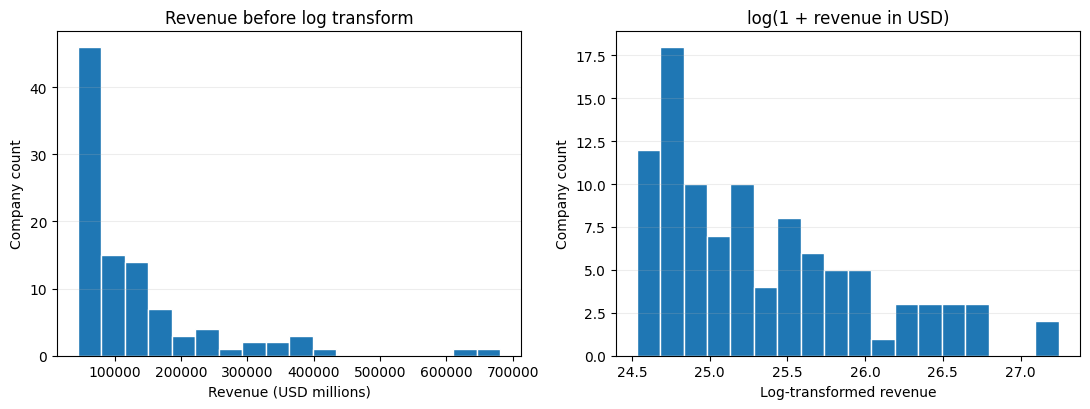

In [ ]:
# Figure 1: skew before and after log transform
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(engineered["Revenue_USD_Millions"], bins=18, edgecolor="white")
axes[0].set_title("Revenue before log transform")
axes[0].set_xlabel("Revenue (USD millions)"); axes[0].set_ylabel("Company count")
axes[1].hist(engineered["Revenue_Log1p"], bins=18, edgecolor="white")
axes[1].set_title("log(1 + revenue in USD)")
axes[1].set_xlabel("Log-transformed revenue"); axes[1].set_ylabel("Company count")
for ax in axes: ax.grid(axis="y", alpha=.22)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "revenue_distribution_log_transform.png", dpi=180, bbox_inches="tight"); plt.show()

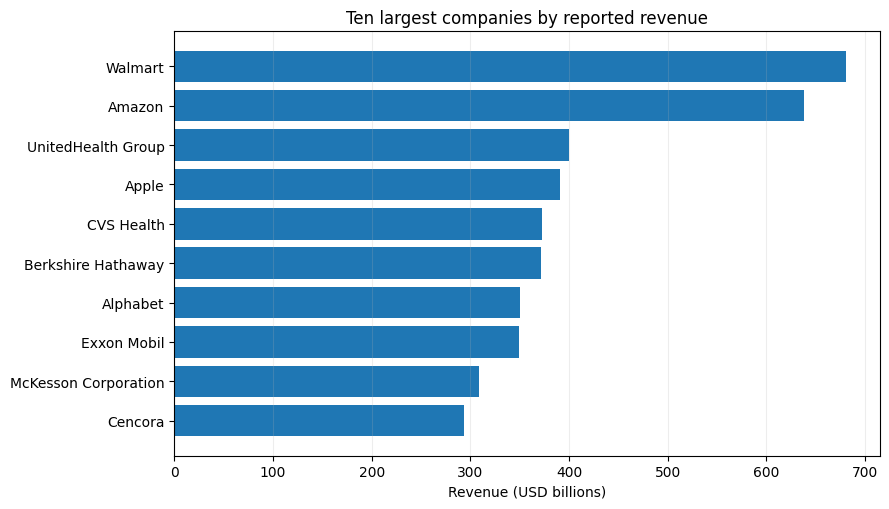

In [ ]:
# Figure 2: ten largest revenues
plot_top = engineered.nlargest(10, "Revenue_USD_Millions").sort_values("Revenue_USD_Millions")
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(plot_top["Company"], plot_top["Revenue_USD_Millions"] / 1000)
ax.set_xlabel("Revenue (USD billions)"); ax.set_title("Ten largest companies by reported revenue")
ax.grid(axis="x", alpha=.22); fig.tight_layout()
fig.savefig(FIGURE_DIR / "top10_revenue.png", dpi=180, bbox_inches="tight"); plt.show()

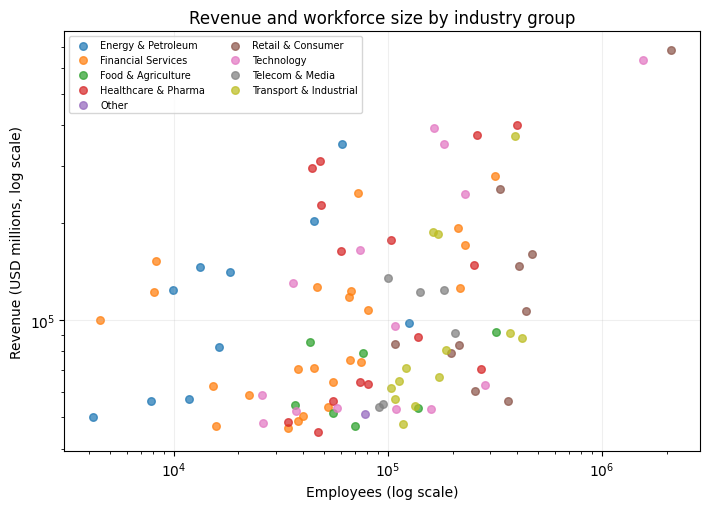

In [ ]:
# Figure 3: scale relation. A log axis allows large and smaller companies to be seen together.
fig, ax = plt.subplots(figsize=(7.2, 5.2))
for group, group_df in engineered.groupby("Industry_Group", dropna=False):
    ax.scatter(group_df["Employees"], group_df["Revenue_USD_Millions"], s=30, alpha=.72, label=group)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Employees (log scale)"); ax.set_ylabel("Revenue (USD millions, log scale)")
ax.set_title("Revenue and workforce size by industry group")
ax.grid(alpha=.2); ax.legend(fontsize=7, loc="best", ncol=2)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "revenue_vs_employees.png", dpi=180, bbox_inches="tight"); plt.show()

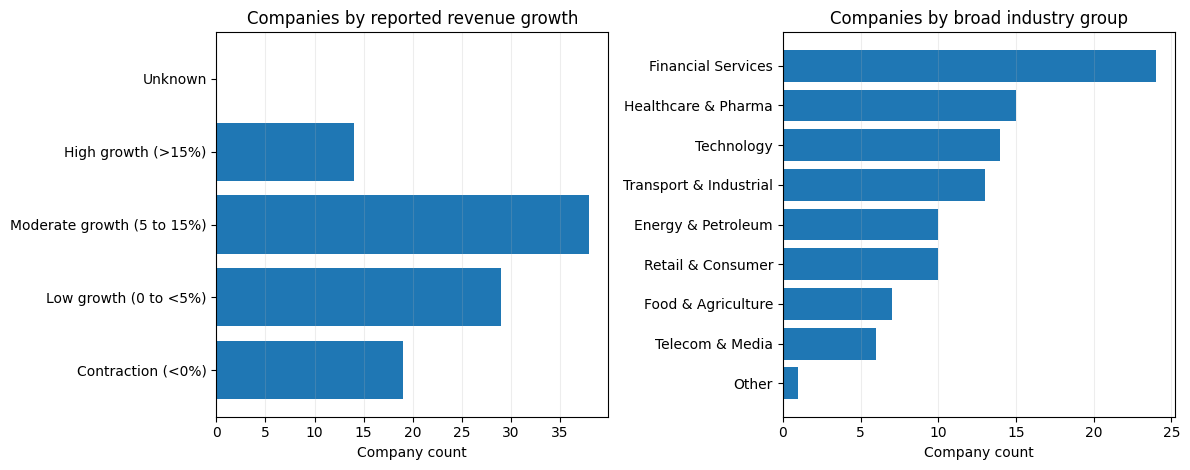

,Company count
Revenue_Growth_Category,
Contraction (<0%),19
Low growth (0 to <5%),29
Moderate growth (5 to 15%),38
High growth (>15%),14
Unknown,0


In [ ]:
# Figure 4: growth categories and broad industry groups
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
growth_order = ["Contraction (<0%)", "Low growth (0 to <5%)", "Moderate growth (5 to 15%)", "High growth (>15%)", "Unknown"]
growth_counts = engineered["Revenue_Growth_Category"].value_counts().reindex(growth_order, fill_value=0)
axes[0].barh(growth_counts.index, growth_counts.values)
axes[0].set_title("Companies by reported revenue growth")
axes[0].set_xlabel("Company count")
industry_counts = engineered["Industry_Group"].value_counts().sort_values()
axes[1].barh(industry_counts.index, industry_counts.values)
axes[1].set_title("Companies by broad industry group")
axes[1].set_xlabel("Company count")
for ax in axes: ax.grid(axis="x", alpha=.22)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "growth_and_industry_groups.png", dpi=180, bbox_inches="tight"); plt.show()
display(growth_counts.rename("Company count").to_frame())

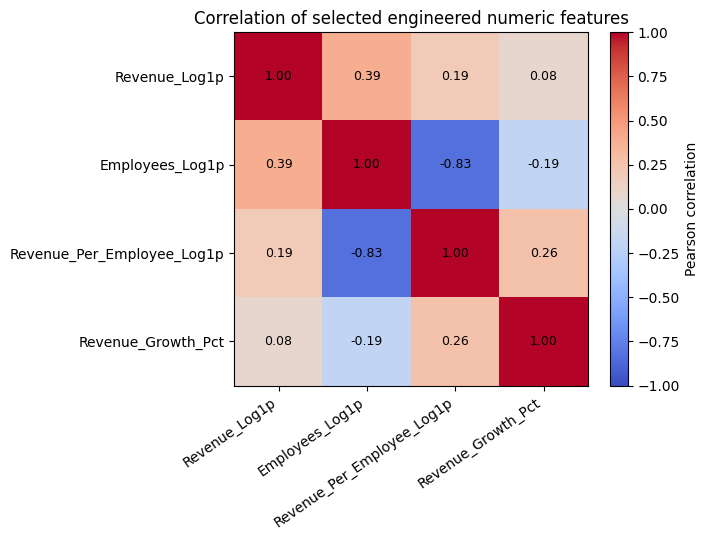

Correlation is an association measure; it does not show cause and effect.


In [ ]:
# Figure 5: correlation among selected continuous features
corr_cols = ["Revenue_Log1p", "Employees_Log1p", "Revenue_Per_Employee_Log1p", "Revenue_Growth_Pct"]
corr = engineered[corr_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=35, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=9)
ax.set_title("Correlation of selected engineered numeric features")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.tight_layout(); fig.savefig(FIGURE_DIR / "feature_correlation.png", dpi=180, bbox_inches="tight"); plt.show()
print("Correlation is an association measure; it does not show cause and effect.")

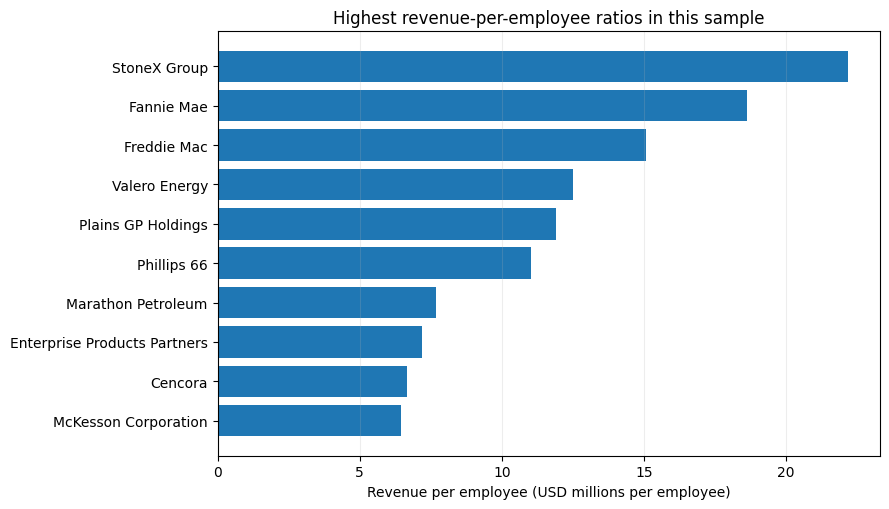

In [ ]:
# Figure 6: revenue per employee (highest values in this sample)
productivity_top = engineered.nlargest(10, "Revenue_Per_Employee_USD").sort_values("Revenue_Per_Employee_USD")
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(productivity_top["Company"], productivity_top["Revenue_Per_Employee_USD"] / 1e6)
ax.set_xlabel("Revenue per employee (USD millions per employee)")
ax.set_title("Highest revenue-per-employee ratios in this sample")
ax.grid(axis="x", alpha=.22); fig.tight_layout()
fig.savefig(FIGURE_DIR / "revenue_per_employee_top10.png", dpi=180, bbox_inches="tight"); plt.show()

## 8. Results and interpretation

Use the following summary to describe what the transformations revealed. The rankings and tiers apply only to this top-100 table; they should not be generalized to all firms.

In [ ]:
raw_revenue_skew = engineered["Revenue_USD_Millions"].skew()
log_revenue_skew = engineered["Revenue_Log1p"].skew()
raw_employee_skew = engineered["Employees"].skew()
log_employee_skew = engineered["Employees_Log1p"].skew()
summary_results = pd.DataFrame([
    ["Rows after cleaning", len(engineered)],
    ["Unique companies", engineered["Company"].nunique()],
    ["Median revenue (USD millions)", engineered["Revenue_USD_Millions"].median()],
    ["Mean revenue (USD millions)", engineered["Revenue_USD_Millions"].mean()],
    ["Minimum revenue growth (%)", engineered["Revenue_Growth_Pct"].min()],
    ["Median revenue growth (%)", engineered["Revenue_Growth_Pct"].median()],
    ["Maximum revenue growth (%)", engineered["Revenue_Growth_Pct"].max()],
    ["Revenue skewness before log", raw_revenue_skew],
    ["Revenue skewness after log", log_revenue_skew],
    ["Employee-count skewness before log", raw_employee_skew],
    ["Employee-count skewness after log", log_employee_skew],
], columns=["Statistic", "Result"])
display(summary_results)
print(f"Revenue skewness changed from {raw_revenue_skew:.2f} to {log_revenue_skew:.2f} after log transform.")
print(f"Employee-count skewness changed from {raw_employee_skew:.2f} to {log_employee_skew:.2f} after log transform.")
print("The transformation compresses skew; it does not remove economic differences between companies.")

# Compact final schema overview for the assignment record.
print("\nFinal engineered data sample:")
display(engineered[["Company", "Industry_Group", "Revenue_USD_Millions", "Revenue_Growth_Pct", "Employees", "Revenue_Per_Employee_USD", "Revenue_Growth_Category", "Revenue_Tier"]].head(12))
print("\nSaved files:")
print(" -", CLEAN_PATH)
print(" -", FEATURE_PATH)
print(" -", FIGURE_DIR)

,Statistic,Result
0,Rows after cleaning,100.000000
1,Unique companies,100.000000
2,Median revenue (USD millions),84784.500000
3,Mean revenue (USD millions),130499.620000
4,Minimum revenue growth (%),-15.600000
5,Median revenue growth (%),5.050000
6,Maximum revenue growth (%),114.200000
7,Revenue skewness before log,2.529879
8,Revenue skewness after log,0.886117
9,Employee-count skewness before log,5.358409


Revenue skewness changed from 2.53 to 0.89 after log transform.
Employee-count skewness changed from 5.36 to -0.22 after log transform.
The transformation compresses skew; it does not remove economic differences between companies.

Final engineered data sample:


,Company,Industry_Group,Revenue_USD_Millions,Revenue_Growth_Pct,Employees,Revenue_Per_Employee_USD,Revenue_Growth_Category,Revenue_Tier
0,Walmart,Retail & Consumer,680985.0,5.1,2100000,3.242786e+05,Moderate growth (5 to 15%),Q4 - highest revenue
1,Amazon,Technology,637959.0,11.0,1556000,4.099994e+05,Moderate growth (5 to 15%),Q4 - highest revenue
2,UnitedHealth Group,Healthcare & Pharma,400278.0,7.7,400000,1.000695e+06,Moderate growth (5 to 15%),Q4 - highest revenue
3,Apple,Technology,391035.0,2.0,164000,2.384360e+06,Low growth (0 to <5%),Q4 - highest revenue
4,CVS Health,Healthcare & Pharma,372809.0,4.2,259500,1.436644e+06,Low growth (0 to <5%),Q4 - highest revenue
5,Berkshire Hathaway,Transport & Industrial,371433.0,1.9,392400,9.465673e+05,Low growth (0 to <5%),Q4 - highest revenue
6,Alphabet,Technology,350018.0,13.9,183323,1.909297e+06,Moderate growth (5 to 15%),Q4 - highest revenue
7,Exxon Mobil,Energy & Petroleum,349595.0,1.5,60900,5.740476e+06,Low growth (0 to <5%),Q4 - highest revenue
8,McKesson Corporation,Healthcare & Pharma,308951.0,11.7,48000,6.436479e+06,Moderate growth (5 to 15%),Q4 - highest revenue
9,Cencora,Healthcare & Pharma,293959.0,12.1,44000,6.680886e+06,Moderate growth (5 to 15%),Q4 - highest revenue



Saved files:
 - /mnt/data/Feature_Engineering_Assignment_Final/clean_company_data.csv
 - /mnt/data/Feature_Engineering_Assignment_Final/engineered_company_features.csv
 - /mnt/data/Feature_Engineering_Assignment_Final/figures


## 9. Connection to future company valuation

The engineered features capture scale, growth and broad business type. In a later stage they could be merged by company and fiscal year with observed market data. The quantities differ:

\[
\text{Market Capitalization}=P\times S,
\]

where \(P\) is the share price and \(S\) is shares outstanding, while

\[
\text{Enterprise Value}=\text{Market Capitalization}+\text{Debt}-\text{Cash}.
\]

Revenue and revenue growth alone are not valuation. A relative multiple such as \(\text{EV}/\text{Revenue}\) requires enterprise value and revenue measured on compatible dates. Historical studies should use only information available at the prediction date, and market value should not be inferred from this table in isolation.

## 10. Conclusion

The raw company table was checked for schema consistency, numeric validity, duplicates and missing values. Feature engineering added currency-unit normalization, revenue per employee, growth-rate conversion and bands, log-transformed scale variables, relative size tiers, standardized and Min-Max features, and broad-industry one-hot features. The histogram and skewness calculations demonstrate why log transforms are useful for heavily right-skewed company data. Extreme observations were retained because they are plausible members of a largest-companies dataset; the IQR rule was used diagnostically rather than as an automatic deletion rule.

**Limitations:** the list reflects a single ranking snapshot, growth definitions can vary by company, revenue per employee is not profit or causal productivity, the industry map is rule-based, and top-100 quartiles are relative to this selected sample. Market capitalization and enterprise value are not present in the dataset. Before prediction, merge vetted historical financial and market records, define a point-in-time target, and fit learned preprocessing only on training data.

## References

1. Wikipedia contributors, “List of largest companies in the United States by revenue,” https://en.wikipedia.org/wiki/List_of_largest_companies_in_the_United_States_by_revenue (table mostly uses fiscal-year 2024 information for the 2025 ranking; accessed for this assignment on 16 October 2026).
2. pandas documentation, `read_html`: https://pandas.pydata.org/docs/reference/api/pandas.read_html.html
3. NumPy documentation, logarithm: https://numpy.org/doc/stable/reference/generated/numpy.log1p.html